In [57]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# ※ WM811K_split/processed 경로에 파일이 생성 되어있다면, 1번은 실행하지 말 것

# 1. 20개 데이터셋 일괄 전처리 후 파일 저장



* 지난 주에는 20개로 분할한 데이터셋 중에서 1개 데이터셋에만 전처리를 했음
* 동일한 전처리를 20개 데이터셋에 모두 적용하고, 결과를 저장해서 계속 사용할 수 있게 처리하자.
    * failureType : 이차원 리스트 안에 저장되어 있는 데이터를 정리해서 새로운 컬럼인 failureType_clean에 저장
    * trianTestLabel : 사용하지 않으므로 제거
    * waferMap의 shape을 구해서 새로운 컬럼인 waferShape에 저장

In [ ]:
# 20개 데이터셋 일괄 전처리 후 파일 저장
import os
import numpy as np
import pandas as pd

# 20개로 분할한 데이터셋이 있는 경로
root_path = '/content/drive/MyDrive/_lec_data/WM811K_split/'

# 전처리 결과 저장할 경로
processed_path = os.path.join(root_path, 'processed')
os.makedirs(processed_path, exist_ok=True)

for i in range(1, 21):

    file_path = os.path.join( root_path, f'LSWMD_{i:02d}.pkl')

    df = pd.read_pickle(file_path)

    # failureType 정리
    df['failureType_clean'] = df['failureType'].apply(
        lambda x: x[0][0] if isinstance(x, np.ndarray) and x.size > 0 else 'None' )

    # waferMap 크기 저장
    df['waferShape'] = df['waferMap'].apply( lambda x: x.shape )

    # 사용하지 않는 컬럼 제거
    df = df.drop( columns=['trianTestLabel'],  errors='ignore' )

    # 전처리 데이터 저장
    save_path = os.path.join( processed_path, f'LSWMD_{i:02d}.pkl' )

    df.to_pickle(save_path)

    print( f'{i:02d} 완료:', len(df), 'rows' )


# 이후에는 전처리된 pickle을 사용할 것이므로, root_path를 변경해두면 편하다.
root_path = processed_path

01 완료: 40573 rows
02 완료: 40573 rows
03 완료: 40573 rows
04 완료: 40573 rows
05 완료: 40573 rows
06 완료: 40573 rows
07 완료: 40573 rows
08 완료: 40573 rows
09 완료: 40573 rows
10 완료: 40573 rows
11 완료: 40573 rows
12 완료: 40573 rows
13 완료: 40573 rows
14 완료: 40573 rows
15 완료: 40573 rows
16 완료: 40573 rows
17 완료: 40573 rows
18 완료: 40572 rows
19 완료: 40572 rows
20 완료: 40572 rows


# 2. 전체 웨이퍼맵 데이터의 분포 탐색하기
* 데이터셋의 특징을 파악하여 학습에 사용할 데이터를 결정하기 위해 전체 데이터 분포를 알 필요가 있다.
* 알아볼 분포는
    * 전체 데이터셋의 클래스별 분포
    * 전체 데이터셋의 waferShape별 분포
    * 전체 데이터셋의 waferShape별 클래스 분포

In [ ]:
root_path = '/content/drive/MyDrive/_lec_data/WM811K_split_processed/'


## Counter 객체를 사용하여 분포를 구해보자.
* Counter는 값의 개수를 누적해서 셀 때 사용하는 객체로, 다른 파일에서 센 결과를 계속 더할 수 있다.

In [58]:
from collections import Counter

class_counts = Counter() # 전체 데이터셋의 클래스별 분포
wafer_shape_counts = Counter() # 전체 데이터셋의 waferShape별 분포
shape_class_counts = Counter() # 전체 데이터셋의 waferShape별 클래스 분포

for i in range(1, 21):
    file_path = os.path.join(root_path, f'LSWMD_{i:02d}.pkl')
    df = pd.read_pickle(file_path)

    class_counts.update( df['failureType_clean'].value_counts().to_dict() )

    wafer_shape_counts.update( df['waferShape'].value_counts().to_dict() )

    shape_class_counts.update(df.groupby(['waferShape', 'failureType_clean']).size().to_dict())

In [70]:
# Counter 객체를 DataFrame으로 바꾼다.

# 전체 데이터셋의 클래스별 분포
class_counts_df = pd.Series(class_counts)

# 전체 데이터셋의 waferShape별 분포
wafer_shape_counts_df = pd.Series(wafer_shape_counts)

# 전체 데이터셋의 waferShape별 클래스 분포
shape_class_counts_df = pd.Series(shape_class_counts)
shape_class_table = shape_class_counts_df.unstack(fill_value=0)


## 분포 시각화하여 데이터 탐색하기
*  Counter로 구해둔 다음 세 가지 항목의 분포를 시각화하여 확인한다.

    * 전체 데이터셋의 클래스별 분포
    * 전체 데이터셋의 waferShape별 분포
    * 전체 데이터셋의 waferShape별 클래스 분포

### ① 전체 데이터셋의 클래스별 분포 확인하기

In [62]:
class_counts_df.head(10)

,0
None,638507
none,147431
Edge-Ring,9680
Edge-Loc,5189
Random,866
Loc,3593
Scratch,1193
Donut,555
Center,4294
Near-full,149


<Axes: >

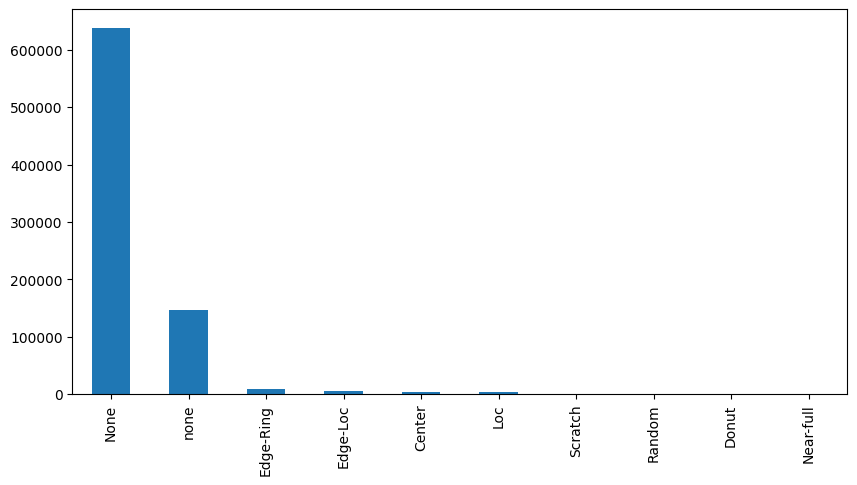

In [63]:

class_counts_df.sort_values(ascending=False).plot(kind='bar', figsize=(10, 5))

### ② 전체 데이터셋의 waferShape별 분포

In [64]:
wafer_shape_counts_df.head()

,,0
33,29,20276
26,26,30078
30,34,29513
40,40,5224
32,29,108687


<Axes: >

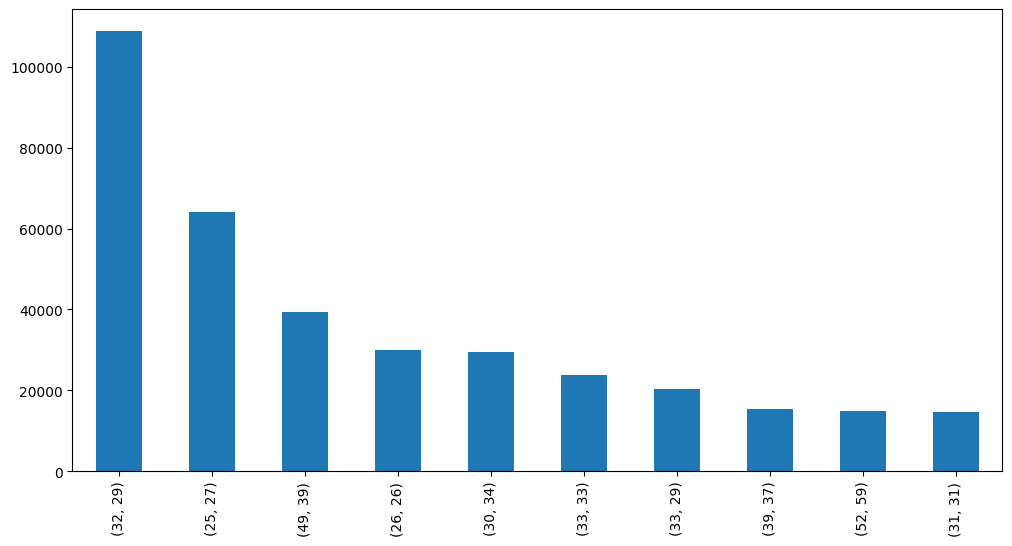

In [65]:
# 2. 전체 데이터셋의 waferShape별 분포
# waferShape가 많은 순서로 주요 shape를 먼저 골라서 확인한다.
major_shapes = wafer_shape_counts_df.sort_values(ascending=False).head(10).index

wafer_shape_counts_df.loc[major_shapes].plot( kind='bar', stacked=True, figsize=(12, 6))

### ③ 전체 데이터셋의 waferShape별 클래스 분포

In [66]:
shape_class_counts_df.head(15)

(12, 27)  None             1
(18, 45)  None             8
(18, 65)  None             1
(24, 71)  None             1
(25, 27)  Edge-Loc       355
          None         45302
(25, 28)  None           309
(26, 25)  Edge-Loc         1
          Edge-Ring        1
          None           288
(26, 26)  Center          90
          Edge-Loc       296
          Edge-Ring       31
          Loc            297
          Near-full       16
dtype: int64

In [71]:
shape_class_table.head(10)

,Center,Donut,Edge-Loc,Edge-Ring,Loc,Near-full,None,Random,Scratch,none
"(6, 21)",0,0,0,0,0,0,1,0,0,0
"(10, 11)",0,0,0,0,0,0,25,0,0,0
"(10, 12)",0,0,0,0,0,0,25,0,0,0
"(10, 150)",0,0,0,0,0,0,595,0,0,0
"(11, 11)",0,0,0,0,0,0,4,0,0,0
"(12, 12)",0,0,0,0,0,0,25,0,0,0
"(12, 27)",0,0,0,0,0,0,1,0,0,0
"(13, 76)",0,0,0,0,0,0,4,0,0,0
"(14, 12)",0,0,0,0,0,0,98,0,0,0
"(14, 13)",0,0,0,0,0,0,8,0,0,0


<Axes: >

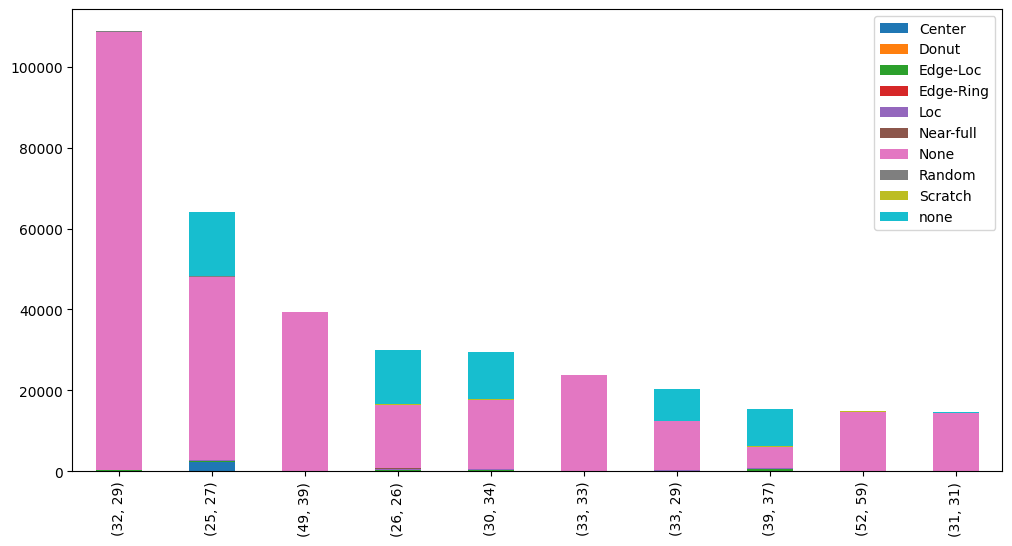

In [69]:
# waferShape가 많은 순서로 주요 shape를 먼저 골라서 확인한다.
major_shapes = wafer_shape_counts_df.sort_values(ascending=False).head(10).index

shape_class_table.loc[major_shapes].plot( kind='bar', stacked=True, figsize=(12, 6))

## 1차 탐색 결과 : None(라벨없음)이 너무 많아서 클래스별 분포를 확인하기 어렵다.
* None을 제외한 분포를 찍어보자.
* 클래스가 None이라는 것은 라벨링이 되어있지 않다는 의미이다.
* 즉 None을 제외한다는 것은 곧 라벨이 있는 데이터만 보겠다는 의미이다.

In [ ]:
# 전체 데이터에서 라벨이 없는 데이터(None인 데이터)가 얼마나 되는지 확인해보자.
print('라벨 없음:', class_counts_df.get('None', 0))
print('전체:', class_counts_df.sum())
print('라벨 없음 비율:', class_counts_df.get('None', 0) / class_counts_df.sum())

라벨 없음: 638507
전체: 811457
라벨 없음 비율: 0.7868648616007996


### ① 전체 데이터셋의 클래스별 분포 확인하기

In [ ]:
class_counts_df.head(10)

,0
None,638507
none,147431
Edge-Ring,9680
Edge-Loc,5189
Random,866
Loc,3593
Scratch,1193
Donut,555
Center,4294
Near-full,149


<Axes: >

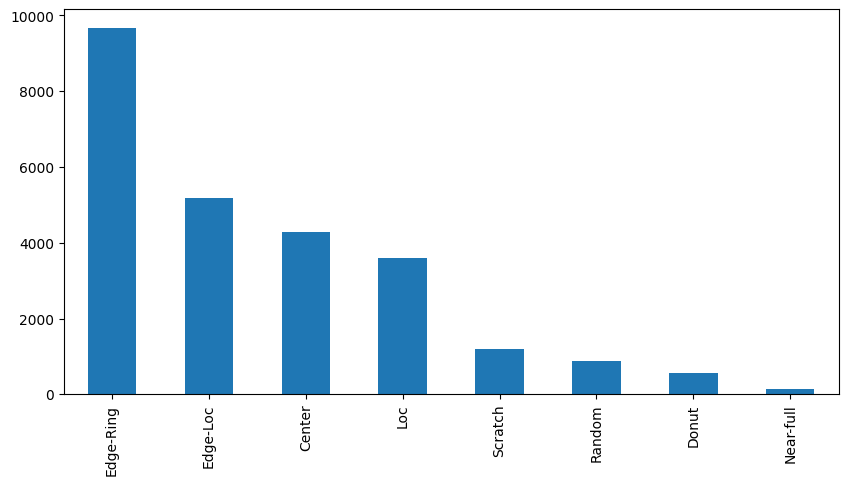

In [83]:
# 기존 코드
# class_counts_df.sort_values(ascending=False).plot(kind='bar', figsize=(10, 5))

# 수정 코드
class_counts_df.drop(labels = ['None', 'none'], errors='ignore').sort_values(ascending=False).plot(kind='bar', figsize=(10, 5))


### ② 전체 데이터셋의 waferShape별 분포

In [ ]:
wafer_shape_counts_df.head()

,,0
33,29,20276
26,26,30078
30,34,29513
40,40,5224
32,29,108687


<Axes: >

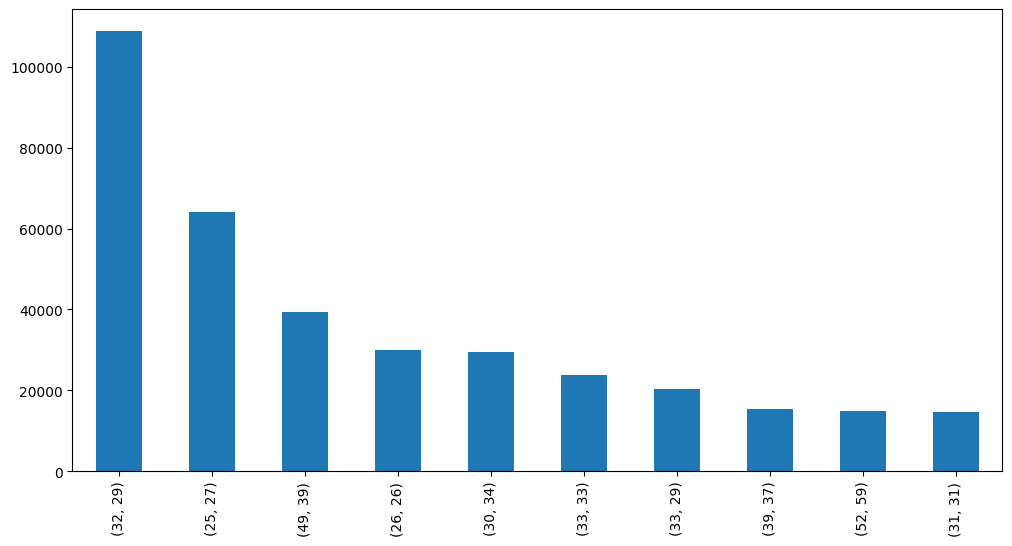

In [ ]:
# 2. 전체 데이터셋의 waferShape별 분포
# waferShape가 많은 순서로 주요 shape를 먼저 골라서 확인한다.
major_shapes = wafer_shape_counts_df.sort_values(ascending=False).head(10).index

wafer_shape_counts_df.loc[major_shapes].plot( kind='bar', stacked=True, figsize=(12, 6))

### ③ 전체 데이터셋의 waferShape별 클래스 분포

In [ ]:
shape_class_counts_df.head(15)

(12, 27)  None             1
(18, 45)  None             8
(18, 65)  None             1
(24, 71)  None             1
(25, 27)  Edge-Loc       355
          None         45302
(25, 28)  None           309
(26, 25)  Edge-Loc         1
          Edge-Ring        1
          None           288
(26, 26)  Center          90
          Edge-Loc       296
          Edge-Ring       31
          Loc            297
          Near-full       16
dtype: int64

In [87]:
shape_class_table.sample(10)

,Center,Donut,Edge-Loc,Edge-Ring,Loc,Near-full,None,Random,Scratch,none
"(52, 46)",0,0,0,0,0,0,168,0,0,0
"(38, 42)",2,0,6,0,6,0,1321,0,1,688
"(65, 64)",0,0,0,0,0,0,25,0,0,0
"(28, 71)",0,0,0,0,0,0,2,0,0,0
"(101, 49)",0,0,0,0,0,0,51,0,0,0
"(56, 52)",0,0,0,0,8,0,392,0,0,0
"(39, 50)",63,0,5,0,16,0,1747,21,6,495
"(72, 72)",4,1,3,30,14,0,5464,0,17,0
"(41, 41)",13,0,27,351,6,1,1704,125,4,936
"(59, 70)",0,0,0,0,0,0,24,0,0,0


In [78]:
shape_class_table.drop(columns=['None'], errors='ignore')

,Center,Donut,Edge-Loc,Edge-Ring,Loc,Near-full,Random,Scratch,none
"(6, 21)",0,0,0,0,0,0,0,0,0
"(10, 11)",0,0,0,0,0,0,0,0,0
"(10, 12)",0,0,0,0,0,0,0,0,0
"(10, 150)",0,0,0,0,0,0,0,0,0
"(11, 11)",0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...
"(155, 175)",0,0,0,0,0,0,0,0,48
"(156, 139)",0,0,0,0,0,0,0,0,0
"(173, 48)",0,0,0,0,0,0,0,0,0
"(212, 84)",2,0,0,0,3,0,0,3,0


<Axes: >

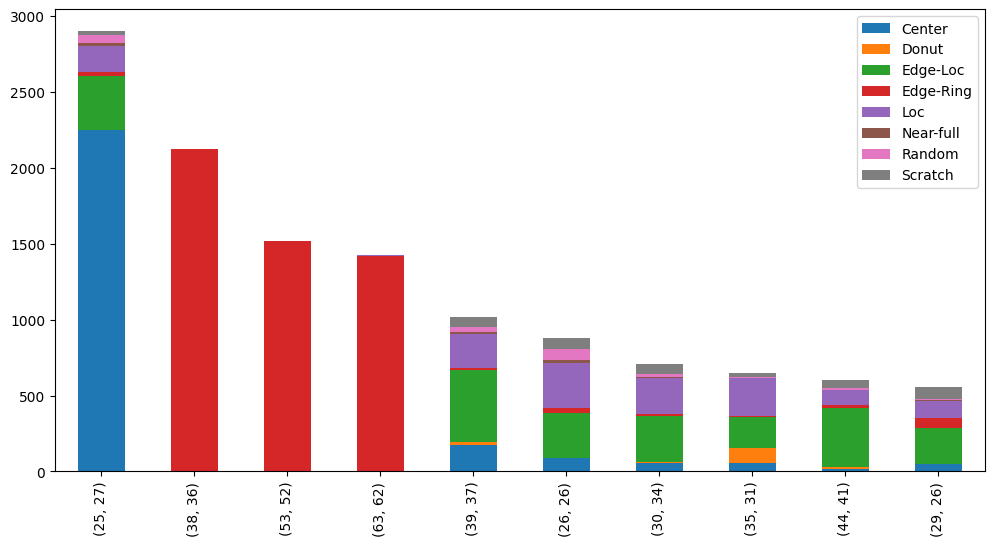

In [91]:
# waferShape가 많은 순서로 주요 shape를 먼저 골라서 확인한다.
# 기존 코드
# major_shapes = wafer_shape_counts_df.sort_values(ascending=False).head(10).index
# 수정 코드
temp_df = shape_class_table.drop(columns=['None', 'none'], errors='ignore')
major_shapes = temp_df.sum(axis=1).sort_values(ascending=False).head(10).index

# 기존 코드
#shape_class_table.loc[major_shapes].plot( kind='bar', stacked=True, figsize=(12, 6))
# 수정 코드
temp_df.loc[major_shapes].plot( kind='bar', stacked=True, figsize=(12, 6))


## 2차 탐색 결과 : none(정상) 역시 너무 많아서 클래스 분포를 확인하기 어렵다.
* **실습 : None을 제외한 코드를 참고 또는 수정하여 None과 none을 제외한 데이터의 분포를 확인해보세요.**

In [ ]:
# 전체 데이터에서 정상인 데이터(클래스가 none인 데이터)가 얼마나 되는지 확인해보자.
print('정상:', class_counts_df.get('none', 0))
print('전체:', class_counts_df.sum())
print('정상 비율:', class_counts_df.get('none', 0) / class_counts_df.sum())

정상: 147431
전체: 811457
정상 비율: 0.1816867683685026


## 3차 탐색 결과 : 학습에 사용할 데이터 확정하기

In [92]:
shape_summary = pd.DataFrame({
    'count': temp_df.sum(axis=1),
    'num_classes': (temp_df > 0).sum(axis=1)
})

print(shape_summary.sort_values( ['count', 'num_classes'], ascending=False).head(20))

print("="*50)

print(shape_summary.sort_values( ['num_classes', 'count'], ascending=False).head(30))


            count  num_classes
(25, 27)     2900            7
(38, 36)     2127            4
(53, 52)     1519            1
(63, 62)     1424            4
(39, 37)     1015            8
(26, 26)      877            8
(30, 34)      710            8
(35, 31)      648            8
(44, 41)      600            8
(29, 26)      555            8
(41, 41)      527            7
(69, 73)      484            2
(107, 150)    470            5
(41, 42)      465            7
(46, 46)      454            5
(43, 42)      453            7
(39, 31)      453            6
(34, 34)      442            7
(32, 29)      413            7
(35, 40)      405            7
          count  num_classes
(39, 37)   1015            8
(26, 26)    877            8
(30, 34)    710            8
(35, 31)    648            8
(44, 41)    600            8
(29, 26)    555            8
(33, 29)    401            8
(41, 33)    307            8
(25, 26)    267            8
(38, 38)    222            8
(25, 27)   2900            7
(

# 3. 웨이퍼맵 1개를 이미지로 변환하여 저장해보기
* 전체 데이터셋을 대상으로 이미지 변환을 적용하기 전에, 웨이퍼맵 1개를 대상으로 테스트한다.

In [93]:
import pandas as pd

# pickle 파일을 하나 불러온다.
file_path = os.path.join(root_path, 'LSWMD_01.pkl')
df = pd.read_pickle(file_path)

# 데이터 확인
print(df.shape)
print(df.columns)
df.head(10)

(40573, 7)
Index(['waferMap', 'dieSize', 'lotName', 'waferIndex', 'failureType',
       'failureType_clean', 'waferShape'],
      dtype='object')


,waferMap,dieSize,lotName,waferIndex,failureType,failureType_clean,waferShape
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,1.0,[[none]],none,"(45, 48)"
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,2.0,[[none]],none,"(45, 48)"
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,3.0,[[none]],none,"(45, 48)"
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,4.0,[[none]],none,"(45, 48)"
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,5.0,[[none]],none,"(45, 48)"
5,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,6.0,[[none]],none,"(45, 48)"
6,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,7.0,[[none]],none,"(45, 48)"
7,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,8.0,[[none]],none,"(45, 48)"
8,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,9.0,[[none]],none,"(45, 48)"
9,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,10.0,[[none]],none,"(45, 48)"


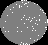

In [95]:
import numpy as np
from PIL import Image
# PIL(Python Imaging Library) : 파이썬에서 이미지 처리를 위해 사용하는 라이브러리

# 웨이퍼맵을 이미지로 변환하여 저장한다.
wafer = df.iloc[5]['waferMap']

# 0, 1, 2 값을 0, 127, 255 픽셀값으로 변환
image_array = (wafer * 127.5).astype(np.uint8)

# array 형태의 데이터로부터 이미지를 만들고, RGB 3채널 이미지로 변환한다.
image = Image.fromarray(image_array).convert("RGB")

# 이미지 파일로 저장한다.
image.save("wafer_sample.png")

# 이미지 확인
display(image)

In [96]:
# 대량 작업의 편의를 위해 웨이퍼맵을 이미지로 저장하는 작업을 함수화한다.
def save_wafer_image(wafer_map, file_path):
    """
    waferMap의 0, 1, 2 값을
    이미지 픽셀값 0, 127, 255로 변환하여 저장한다.
    """

    image_array = (
        wafer_map * 127.5
    ).astype(np.uint8)

    image = Image.fromarray(
        image_array
    ).convert("RGB")

    image.save(file_path)

# 함수 사용 예시
# save_wafer_image(df.iloc[0]['waferMap'], "wafer_sample.png")

# 4. 학습에 사용할 데이터 정리하기
* 1단계
    * 나중의 편의를 위해 None, none 제외한 전체 데이터를 하나의 pickle로 저장해둔다.
    * 즉, 불량인 데이터만을 따로 모은 pickle 파일을 만드는 셈이다.

* 2단계
    * 웨이퍼맵을 이미지 파일로 변환하여 저장한다.
    * 전체 데이터를 변환하진 않는다.
        * 데이터 개수가 많은 상위 5개의 클래스
        * 클래스별 동일한 개수의 데이터를 랜덤으로 샘플링

## 1단계. None, none 제외한 전체 데이터를 하나의 pickle로 저장

In [ ]:
import os
import pandas as pd

# =========================
# 경로 설정
# =========================

# root_path : 제일 처음 일괄로 전처리한 20개 데이터셋이 위치한 폴더의 경로
root_path = '/content/drive/MyDrive/_lec_data/WM811K_split_processed/'
# output_path : None, none 제외한 전체 데이터를 저장할 경로
output_path = os.path.join(root_path, "LSWMD_labeled.pkl")

# =========================
# 20개 데이터셋에서 라벨 있는 데이터만 수집
# =========================
data_list = []

for i in range(1, 21):
    file_path = os.path.join(
        root_path,
        f"LSWMD_{i:02d}.pkl"
    )

    df = pd.read_pickle(file_path)

    # 라벨이 없는 데이터와 정상 데이터 제외
    filtered_df = df[
        (df["failureType_clean"] != "None") &
        (df["failureType_clean"] != "none")
    ].copy()

    # 나중에 원본 추적이 필요할 수도 있으므로 출처 기록
    filtered_df["source_file"] = f"LSWMD_{i:02d}.pkl"
    filtered_df["source_index"] = filtered_df.index

    data_list.append(filtered_df)

    print(
        f"{i:02d}번 파일:",
        len(filtered_df),
        "개"
    )

# =========================
# 하나의 DataFrame으로 통합
# =========================
labeled_df = pd.concat(
    data_list,
    ignore_index=True
)

# =========================
# pickle 저장
# =========================
labeled_df.to_pickle(output_path)

print()
print("저장 완료!")
print("전체 데이터 수:", len(labeled_df))
print("저장 위치:", output_path)

## 2단계. 상위 5개 클래스에서 같은 개수만큼 이미지 저장

In [ ]:
import os
import numpy as np
import pandas as pd
from PIL import Image

# =========================
# 설정값
# =========================
# 1단계에서 만든 pikcle 파일의 경로
DATA_PATH = os.path.join( root_path, "LSWMD_labeled.pkl")
# 이미지가 저장될 경로
OUTPUT_DIR = os.path.join( root_path, "wafer_images")

# 각 클래스별로 이미지로 만들 데이터의 개수
SAMPLE_PER_CLASS = 500

# 대상 클래스
TARGET_CLASSES = [
    "Edge-Ring",
    "Edge-Loc",
    "Center",
    "Loc",
    "Scratch"
]

# 랜덤 시드
RANDOM_STATE = 42

In [ ]:
# pickle 불러오기
df = pd.read_pickle(DATA_PATH)
# df["failureType_clean"].value_counts()

# 사용할 5개 클래스만 선택
target_df = df[ df["failureType_clean"].isin( TARGET_CLASSES )].copy()

# 확인
target_df["failureType_clean"].value_counts()

In [ ]:
# 클래스별 동일한 개수의 데이터를 랜덤으로 골라 모아온다.
sampled_list = []

for class_name in TARGET_CLASSES:

    class_df = target_df[ target_df["failureType_clean"] == class_name ]

    sampled_df = class_df.sample(
        n=SAMPLE_PER_CLASS,
        random_state=RANDOM_STATE
    )

    sampled_list.append(sampled_df)

sampled_df = pd.concat( sampled_list, ignore_index=True )

# 확인
sampled_df["failureType_clean"].value_counts()

In [ ]:
# 클래스별로 이미지를 저장할 폴더를 만든다.
os.makedirs( OUTPUT_DIR, exist_ok=True )

for class_name in TARGET_CLASSES:
    class_folder = os.path.join( OUTPUT_DIR, class_name )
    os.makedirs( class_folder, exist_ok=True )


In [ ]:
# 웨이퍼맵 데이터를 이미지로 변환하여 앞서 생성한 폴더에 저장한다.
for idx, row in sampled_df.iterrows():

    class_name = row["failureType_clean"]
    source_name = row["source_file"].replace(".pkl", "")
    source_index = row["source_index"]

    file_name = (
        f"{class_name}_"
        f"{source_name}_"
        f"{source_index}.png"
    )

    file_path = os.path.join(
        OUTPUT_DIR,
        class_name,
        file_name
    )

    save_wafer_image(
        row["waferMap"],
        file_path
    )

In [ ]:
# 마지막으로 저장 결과를 확인한다.
for class_name in TARGET_CLASSES:
    class_folder = os.path.join( OUTPUT_DIR, class_name )
    image_count = len( os.listdir(class_folder) )

    print( class_name, ":", image_count )

# 5. TM에서 만든 모델 : animal data

In [ ]:
# TM에서 저장한 keras 모델의 버전 문제로 인해, 코렙에서 불러올 때 tf_keras를 사용해야 한다.
!pip install tf_keras

In [ ]:
import tf_keras
from tensorflow.keras.models import load_model

# 모델 로딩하기 : TM에서 저장한 모델의 경로로 수정해야 한다.
tm_path = '/content/drive/MyDrive/_lec_data/AIVision_2026/converted_keras_animal/keras_model.h5'
model = tf_keras.models.load_model(tm_path, compile=False)

model.summary()

In [ ]:
print(model.input_shape)
print(model.output_shape)

In [ ]:
# ==============================
# TM에서 제공하는 코드
# - 모델을 로딩하는 코드가 있지만, 그대로 사용하면 버전 문제로 오류가 발생한다.
#   → 모델은 tf_keras로 로딩
#
# - 모델 로딩 후에는 오류 없이 이미지 1장에 대한 모델 예측값을 구해볼 수 있다.
#
# - 수정해야 하는 부분
#   → TM에서 모델 저장 시 함께 저장된 labels.txt의 경로를 지정해줘야 한다.
#   → 입력으로 사용할 이미지의 경로를 지정해줘야 한다.
#
# - 실습: animal dataset의 이미지 1장에 대해 모델 예측값을 확인한다.
# ==============================

from keras.models import load_model  # TensorFlow is required for Keras to work
from PIL import Image, ImageOps  # Install pillow instead of PIL
import numpy as np

# # Disable scientific notation for clarity
# np.set_printoptions(suppress=True)

# # Load the model
# model = load_model("keras_Model.h5", compile=False)

# Load the labels
class_names = open("/content/drive/MyDrive/_lec_data/AIVision_2026/converted_keras_animal/labels.txt", "r").readlines()   # 여기 수정

# Create the array of the right shape to feed into the keras model
# The 'length' or number of images you can put into the array is
# determined by the first position in the shape tuple, in this case 1
data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)

# Replace this with the path to your image
image = Image.open("/content/drive/MyDrive/_lec_data/animals/dogs_00023.jpg").convert("RGB")    # 여기 수정

display(image)

# resizing the image to be at least 224x224 and then cropping from the center
size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)

display(image)

# turn the image into a numpy array
image_array = np.asarray(image)

# Normalize the image
normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1

# Load the image into the array
data[0] = normalized_image_array

# Predicts the model
prediction = model.predict(data)
index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

# Print prediction and confidence score
print("Class:", class_name[2:], end="")
print("Confidence Score:", confidence_score)


# 6. TM에서 만든 모델 : wafermap data

## 모델 로딩 후 동작 테스트
* animal dataset 실습과 동일하게, 모델을 로딩하고 웨이퍼맵 이미지 1장에 대해 모델의 예측값을 구해본다.

In [ ]:
import tf_keras

# 모델 로딩하기 : TM에서 저장한 모델의 경로를 지정해줘야 한다.
model = tf_keras.models.load_model(
    "/content/drive/MyDrive/_lec_data/AIVision_2026/converted_keras_wafermap/keras_model.h5",
    compile=False
)


In [ ]:
model.summary()
print(model.input_shape)
print(model.output_shape)

In [ ]:
# ==============================
# TM에서 제공하는 코드
# - 모델을 로딩하는 코드가 있지만, 그대로 사용하면 버전 문제로 오류가 발생한다.
#   → 모델은 tf_keras로 로딩
#
# - 모델 로딩 후에는 오류 없이 이미지 1장에 대한 모델 예측값을 구해볼 수 있다.
#
# - 수정해야 하는 부분
#   → TM에서 모델 저장 시 함께 저장된 labels.txt의 경로를 지정해줘야 한다.
#   → 입력으로 사용할 이미지의 경로를 지정해줘야 한다.
#
# - 실습: 웨이퍼맵 이미지 1장에 대해 모델 예측값을 확인한다.
# ==============================

from keras.models import load_model  # TensorFlow is required for Keras to work
from PIL import Image, ImageOps  # Install pillow instead of PIL
import numpy as np

# # Disable scientific notation for clarity
# np.set_printoptions(suppress=True)

# # Load the model
# model = load_model("keras_Model.h5", compile=False)

# Load the labels
class_names = open("/content/drive/MyDrive/_lec_data/AIVision_2026/converted_keras_wafermap/labels.txt", "r").readlines()

# Create the array of the right shape to feed into the keras model
# The 'length' or number of images you can put into the array is
# determined by the first position in the shape tuple, in this case 1
data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)

# Replace this with the path to your image
image = Image.open("/content/drive/MyDrive/_lec_data/AIVision_2026/Test/Loc/Loc_LSWMD_01_12781.png").convert("RGB")

display(image)

# resizing the image to be at least 224x224 and then cropping from the center
size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)

display(image)

# turn the image into a numpy array
image_array = np.asarray(image)

# Normalize the image
normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1

# Load the image into the array
data[0] = normalized_image_array

# Predicts the model
prediction = model.predict(data)
index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

# Print prediction and confidence score
print("Class:", class_name[2:], end="")
print("Confidence Score:", confidence_score)


In [ ]:
# 웨이퍼맵에서 ImageOps.fit()이 어떤 이미지를 만들어내는지 확인하기
original = Image.open("/content/drive/MyDrive/_lec_data/AIVision_2026/Test/Loc/Loc_LSWMD_01_12781.png").convert("RGB")

processed = ImageOps.fit(
    original,
    (224, 224),
    Image.Resampling.LANCZOS
)

display(original)
display(processed)

## 테스트 데이터 전체에 대해 모델의 예측값을 구하기

In [ ]:
import os
import numpy as np
import pandas as pd
from PIL import Image, ImageOps

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt

In [ ]:
# TM에서 모델 저장 시 함께 저장된 labels.txt의 경로
label_path = "/content/drive/MyDrive/_lec_data/AIVision_2026/converted_keras_wafermap/labels.txt"

# label.txt 내용으로부터 클래스 정보를 가져온다.
class_names = [
    line.strip().split(" ", 1)[1]
    for line in open(label_path, "r").readlines()
]

print(class_names)

In [ ]:
# TM에서 제공하는 코드가 해줬던 처리를 함수화 한다.
# - 어떤 크기의 이미지가 들어오더라도 모델에 입력할 수 있도록
# - shape과 정규화 등 입력 이미지를 학습 데이터와 동일한 형태로 만들어준다.
def preprocess_tm_image(image_path):
    image = Image.open(image_path).convert("RGB")

    image = ImageOps.fit( image, (224, 224), Image.Resampling.LANCZOS )
    image_array = np.asarray(image)
    normalized_image_array = ( image_array.astype(np.float32) / 127.5 ) - 1

    data = np.ndarray( shape=(1, 224, 224, 3), dtype=np.float32 )
    data[0] = normalized_image_array

    return data

In [ ]:
# 테스트 데이터의 예측값(y_pred)을 구한다.

# 테스트 데이터셋이 있는 폴더의 경로
# 이 폴더 내에는 각 클래스 이름의 폴더가 있고, 해당 폴더 내에 테스트용 이미지가 있다고 전제한다.
TEST_DIR = "/content/drive/MyDrive/_lec_data/AIVision_2026/Test/"

y_true = [] # 테스트 이미지의 정답 라벨을 저장할 리스트
y_pred = [] # 모델 예측값을 저장할 리스트

for class_name in class_names:

    class_dir = os.path.join( TEST_DIR, class_name )

    for file_name in os.listdir(class_dir):

        if not file_name.lower().endswith((".png", ".jpg", ".jpeg")):
            continue

        file_path = os.path.join( class_dir, file_name )
        data = preprocess_tm_image( file_path )

        prediction = model.predict( data, verbose=0 )

        pred_index = np.argmax( prediction )
        pred_class = class_names[ pred_index ]

        y_true.append( class_name )
        y_pred.append( pred_class )

## 모델 성능 지표 확인하기
* 테스트 데이터의 모델 예측값을 토대로 모델의 성능 지표를 확인해본다.
    * 모델의 정확도 (accuracy_score)
    * 분류 보고서 (classification_report)
    * 혼동 행렬 (confusion_matrix)

In [ ]:
# 테스트 데이터에 대한 모델의 정확도를 확인한다.
accuracy = accuracy_score( y_true, y_pred )

print(f"Accuracy: {accuracy:.4f}")

In [ ]:
# classification_report를 출력한다.
print(
    classification_report(
        y_true,
        y_pred,
        labels=class_names,
        target_names=class_names
    )
)

In [ ]:
# 혼동 행렬을 출력한다.
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=class_names
)

print(cm)

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

# 혼동 행렬 시각화
# - 기존에는 heatmap을 사용하여 시각화하였으나, ConfusionMatrixDisplay를 사용해본다.
disp = ConfusionMatrixDisplay( confusion_matrix=cm, display_labels=class_names )

disp.plot( xticks_rotation=45 )
plt.show()

In [ ]:
# 틀린 이미지가 무엇인지, 파일명을 따로 기록해둔다.
# - 모델이 헷갈려한 데이터의 특성을 가늠해볼 수 있다.

errors = []

for class_name in class_names:
    class_dir = os.path.join( TEST_DIR, class_name )

    for file_name in os.listdir(class_dir):
        if not file_name.lower().endswith((".png", ".jpg", ".jpeg")):
            continue

        file_path = os.path.join( class_dir, file_name )
        data = preprocess_tm_image( file_path )

        prediction = model.predict( data, verbose=0 )
        pred_index = np.argmax( prediction )

        pred_class = class_names[ pred_index ]

        if pred_class != class_name:
            errors.append({
                "file_name": file_name,
                "true": class_name,
                "pred": pred_class,
                "confidence": float(
                    prediction[0][pred_index]
                )
            })

In [ ]:
# 확신하면서 틀린 이미지가 있는지, 있다면 무엇인지 확인해본다.
error_df = pd.DataFrame(errors)

error_df.sort_values( "confidence", ascending=False )

# 7. 직접 CNN 모델 만들기 : wafermap data
* TM에서 만든 모델의 성능이 좋지 못하므로, 웨이퍼맵 이미지 데이터를 직접 학습시켜 CNN 모델을 만들어보자.
* 이후 직접 만든 CNN 모델의 성능을 TM 모델과 비교해보자.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# 모델 학습에 필요한 설정값(하이퍼파라미터)을 상수로 관리해보자.
IMG_SIZE = 64
BATCH_SIZE = 32
EPOCHS = 10

# 훈련 데이터와 테스트 데이터의 경로
TRAIN_DIR = "/content/drive/MyDrive/_lec_data/AIVision_2026/Train/"
TEST_DIR = "/content/drive/MyDrive/_lec_data/AIVision_2026/Test/"

In [ ]:
# image_dataset_from_directory를 사용하여 데이터의 크기를 맞춰준다.

# 학습 데이터셋
train_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

# 검증 데이터셋
val_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

# 테스트 데이터셋
test_ds = keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

In [ ]:
# image_dataset_from_directory의 결과를 확인한다.

# 클래스 순서 확인 : ['Center', 'Edge-Loc', 'Edge-Ring', 'Loc', 'Scratch']
class_names = train_ds.class_names
print(class_names)


# 데이터 shape 확인 : (32, 64, 64, 3)
# 32 = batch size
# 64, 64 = resize된 크기
# 3 = RGB 채널.
for images, labels in train_ds.take(1):
    print(images.shape)


In [ ]:
# 정규화
# - image_dataset_from_directory로 만든 데이터는 기존에 하던 방식으로 정규화하는 과정이 번거롭다.
# - Rescaling layer를 사용하여 정규화 작업을 모델의 층 안에 넣는 방식을 써보자.
normalization_layer = layers.Rescaling(1./255)

In [ ]:
# 모델 생성
model = keras.Sequential([
    keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    normalization_layer,  # 정규화 작업하는 층

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(len(class_names), activation="softmax")
])

model.summary()

In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

In [ ]:
# 테스트 데이터로 정확도 체크
test_loss, test_acc = model.evaluate(test_ds)

print("Test accuracy:", test_acc)

In [ ]:
# 테스트 데이터의 예측값(y_pred)을 구한다.

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)
    pred_labels = np.argmax( predictions, axis=1 )

    y_true.extend( labels.numpy() )
    y_pred.extend( pred_labels )

In [ ]:
# 분류 리포트
print( classification_report( y_true, y_pred, target_names=class_names ) )

In [ ]:
# 혼동행렬
cm = confusion_matrix( y_true, y_pred )

disp = ConfusionMatrixDisplay( confusion_matrix=cm,
                              display_labels=class_names )

disp.plot( xticks_rotation=45 )
plt.show()
